In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move_special import *
import pygame

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/phd/pytorch_DGN/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [2]:
def create_graph_from_grid(grid):
    rows, cols = grid.shape
    G = nx.Graph()

    # Get all active nodes (where grid == 1)
    nodes = np.argwhere(grid == 1)
    G.add_nodes_from(map(tuple, nodes))  # Convert to tuple for hashability

    # Define the 8 possible moves
    directions = np.array([[-1, -1], [-1, 0], [-1, 1],
                           [0, -1],          [0, 1],
                           [1, -1],  [1, 0],  [1, 1]])

    # Compute valid neighbor coordinates with periodic boundaries
    for r, c in nodes:
        for dr, dc in directions:
            nr = (r + dr) % rows  # Wrap around row boundaries
            nc = (c + dc) % cols  # Wrap around column boundaries
            if grid[nr, nc] == 1:  # Only add edges if the neighbor is also 1
                G.add_edge((r, c), (nr, nc))

    return G
    
def get_largest_connected_component(G):
    try:
        largest_cc = max(nx.connected_components(G), key=len)
        return G.subgraph(largest_cc).copy()
    except ValueError: 
        return nx.Graph() 

In [3]:
n = 300
Lx = 32
Ly = 32
eta = 0.01
decay_rate = 0.015
beta = 4.5
delta = 0.3
n_special = 30
t_transient = 200
tmax = 1200
eta_special = 1
beta_special = 4.5
delta_special = 0.3

In [4]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0 = (n*eta + n_special*eta_special)/(decay_rate*Lx**2)

In [5]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]

In [ ]:
positions = np.zeros((len(beta_list), len(delta_list), n, 2))
pheromones = np.zeros((len(beta_list), len(delta_list), Lx, Ly))
max_counter = np.zeros((len(beta_list), len(delta_list), 1))

all_positions = np.zeros((tmax-t_transient, n+n_special, 2))
all_pheromones = np.zeros((tmax-t_transient, Lx, Ly))

for beta in beta_list:
    for delta in delta_list:
        print(f"Testing with delta = {delta}, beta = {beta}")

        env = Ants_move_special(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                  beta, delta, tmax, n_special, t_transient) # in this case beta, delta are beta and delta also for special ants
        
        env.reset_objects()
        env.transient()
        
        for t in range(tmax-t_transient):
            env.update()
            all_positions[t, :, :] = env.positions.copy()
            all_pheromones[t, :, :] = env.pheromones.copy()

        all_positions = np.array(all_positions)
        all_pheromones = np.array(all_pheromones)
        np.savez(f"test_results_delta_{delta}_beta_{beta}.npz", all_positions=all_positions, all_pheromones=all_pheromones)

Testing with delta = 0.3, beta = 3.5
Testing with delta = 0.4, beta = 3.5
Testing with delta = 0.5, beta = 3.5
Testing with delta = 0.6, beta = 3.5
Testing with delta = 0.7, beta = 3.5
Testing with delta = 0.8, beta = 3.5
Testing with delta = 0.3, beta = 4.5
Testing with delta = 0.4, beta = 4.5
Testing with delta = 0.5, beta = 4.5
Testing with delta = 0.6, beta = 4.5
Testing with delta = 0.7, beta = 4.5
Testing with delta = 0.8, beta = 4.5
Testing with delta = 0.3, beta = 5.5
Testing with delta = 0.4, beta = 5.5
Testing with delta = 0.5, beta = 5.5
Testing with delta = 0.6, beta = 5.5
Testing with delta = 0.7, beta = 5.5
Testing with delta = 0.8, beta = 5.5
Testing with delta = 0.3, beta = 6.5
Testing with delta = 0.4, beta = 6.5
Testing with delta = 0.5, beta = 6.5
Testing with delta = 0.6, beta = 6.5
Testing with delta = 0.7, beta = 6.5
Testing with delta = 0.8, beta = 6.5
Testing with delta = 0.3, beta = 7.5
Testing with delta = 0.4, beta = 7.5
Testing with delta = 0.5, beta = 7.5
T

In [24]:
# Parametri della simulazione per comporre il nome del file
n_sim = 1
beta = beta_list
delta = delta_list

entropy_results = np.zeros((n_sim, len(beta), len(delta)))
for sim in range(n_sim):
    for b in beta:
        for d in delta:

            path = f"test_results_delta_{d}_beta_{b}.npz"

            # 1. Carica il file .npz
            data = np.load(path)
            pos = data["all_positions"]  # Shape: (tmax-t_transient, n+n_special, 2)

            # 2. Estrai gli ultimi T=100 time step e i primi n individui (escludendo eventuali speciali)
            pos_last_100 = pos[-100:, :n]  # Shape: (100, 330, 2)

            # 3. Trasforma in una matrice di punti (N_osservazioni, 2)
            # N_osservazioni = 100 * 330 = 33000
            points = pos_last_100.reshape(-1, 2)

            # 4. Calcola l'istogramma 2D per discretizzare lo spazio in celle (es. 20x20)
            num_bins_per_side = 20
            hist, xedges, yedges = np.histogram2d(
                points[:, 0], 
                points[:, 1], 
                bins=num_bins_per_side
            )

            # 5. Calcola le probabilità di occupazione
            total_points = len(points)
            p = hist / total_points

            # Considera solo le celle con probabilità > 0 (evita log2(0))
            p_non_zero = p[p > 0]

            # 6. Calcolo dell'Entropia di Shannon
            H = -np.sum(p_non_zero * np.log2(p_non_zero))

            # 7. Normalizzazione (rispetto al massimo teorico della griglia M = bins * bins)
            M = num_bins_per_side ** 2
            H_max = np.log2(M)
            H_norm = H / H_max

            entropy_results[sim, beta.index(b), delta.index(d)] = H_norm

Text(0, 0.5, '$\\beta$')

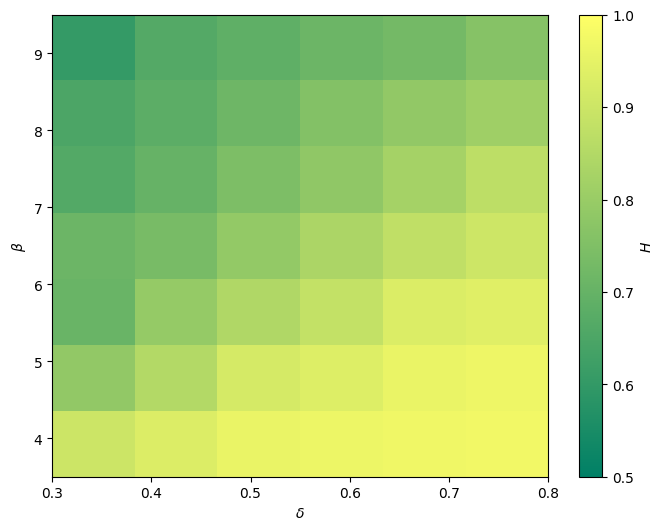

In [26]:
plt.figure(figsize=(8, 6))
entropy_results = np.mean(entropy_results, axis=0)  # Media su tutte le simulazioni
plt.imshow(entropy_results, origin='lower', extent=[min(delta_list), max(delta_list), min(beta_list), max(beta_list)],
            aspect='auto', cmap='summer', vmin=0.5, vmax=1)
plt.colorbar(label=r'${H}$')
plt.xlabel(r'$\delta$')  
plt.ylabel(r'$\beta$')

In [40]:
individual_entropy_results = np.zeros((len(beta), len(delta)))
individual_entropy_std_results = np.zeros((len(beta), len(delta)))

for b in beta:
    for d in delta:

        # 1. Carica il file .npz
        filename = f"test_results_delta_{d}_beta_{b}.npz"
        data = np.load(filename)
        pos = data['all_positions']  # Shape: (1000, 330, 2)

        # 2. Ultimi 100 time step e primi n individui
        pos_last_100 = pos[-100:, :n]
        num_timesteps, num_ants, _ = pos_last_100.shape

        # 3. Entropia di ciascuna formica (formula del paper, celle native 32x32)
        individual_entropies = np.zeros(num_ants)

        for i in range(num_ants):
            ant_trajectory = pos_last_100[:, i, :]   # (100, 2)

            # V_ij: numero di visite alla cella j (celle uniche = location uniche)
            _, V = np.unique(ant_trajectory, axis=0, return_counts=True)
            k = len(V)

            if k > 1:
                p = V / V.sum()
                individual_entropies[i] = -np.sum(p * np.log2(p))
            else:
                # k = 1 -> log(1) = 0, formula indefinita: convenzione D = 0
                individual_entropies[i] = 0.0

        # 4. Media e deviazione standard tra le formiche
        bi, di = beta.index(b), delta.index(d)
        individual_entropy_results[bi, di] = np.mean(individual_entropies)
        individual_entropy_std_results[bi, di] = np.std(individual_entropies)

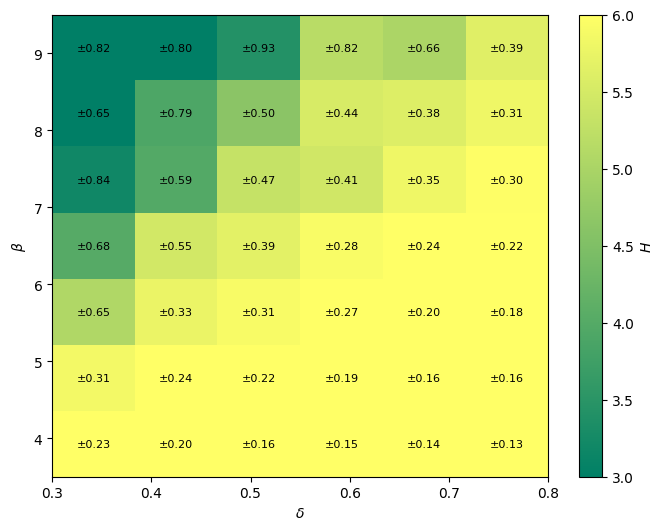

In [42]:
plt.figure(figsize=(8, 6))
avg_entropy = individual_entropy_results
std_entropy = individual_entropy_std_results

xmin, xmax = min(delta), max(delta)
ymin, ymax = min(beta), max(beta)

plt.imshow(
    avg_entropy,
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='summer',
    vmin=3,
    vmax=6
)
plt.colorbar(label=r'${H}$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')

n_rows, n_cols = std_entropy.shape

# Calcolo delle dimensioni di una singola cella
dx = (xmax - xmin) / n_cols
dy = (ymax - ymin) / n_rows

# Calcolo dei centri esatti di ogni cella
x_centers = xmin + (np.arange(n_cols) + 0.5) * dx
y_centers = ymin + (np.arange(n_rows) + 0.5) * dy

# Inserimento del testo perfettamente al centro
for i in range(n_rows):
  for j in range(n_cols):
    val = std_entropy[i, j]
    plt.text(
        x_centers[j],
        y_centers[i],
        f'±{val:.2f}',
        ha='center',
        va='center',
        color='black',
        fontsize=8,
    )